In [1]:
import os, json, time, hashlib
from urllib.request import urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import KFold
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM

# Set experiment options
MODEL_NAME = os.environ.get("PAIN_AXIS_MODEL", "Qwen/Qwen2.5-0.5B")
QUICK = os.environ.get("PAIN_AXIS_QUICK", "0") == "1"

DATA_REPO = "valen-research/Pain-axis"
DATA_COMMIT = "213fb6c89c96004dbe93d1704c636ad8c9d801f3"
DATA_FILES = ["3.1_pain_and_control_datasets.json", "3.1_sadness_dataset.json"]

SEED = 42
N_FOLDS = 5
DENOISE_VARIANCE = 0.5
N_RANDOM_DIRECTIONS = 100 if QUICK else 1000
N_BOOTSTRAP = 200 if QUICK else 2000

PILOT_HIDDEN_STATE_INDEX = 10
PILOT_N_PER_CATEGORY = 2
PILOT_SEED = 42
PILOT_REPORTED = {"raw_norm": 1.828266978263855, "denoised_norm": 1.6353118419647217,
                  "n_components": 2, "cosine_raw_denoised": 0.894460141658783}

PAIN = ["A1", "A2", "A3", "A4", "A5"]
CONTROL = ["B", "C1", "C2", "D", "E"]
NEUTRAL = "D"
DATASETS = ["S2_1P", "S2_3P", "S1_1P", "S1_3P", "Random_1P", "Random_3P", "Arousal_1P", "Arousal_3P",
            "Numb_1P", "Numb_3P", "ControlSupplement_1P", "SD_sadness_1P", "SD_sadness_3P"]

DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
DTYPE = torch.float32

np.random.seed(SEED)
torch.manual_seed(SEED)
print(f"model={MODEL_NAME}  device={DEVICE}  quick={QUICK}")
print(f"torch {torch.__version__} | transformers {transformers.__version__} | numpy {np.__version__} | pandas {pd.__version__}")


model=Qwen/Qwen2.5-0.5B  device=mps  quick=False
torch 2.14.1 | transformers 5.20.1 | numpy 2.4.2 | pandas 2.3.3


## Paper results


In [2]:
# Paper comparison values
PAPER_RANGE = {
    "S2 held-out AUC (5-fold)":      (0.91, 1.00),
    "S2 in-sample AUC":              (0.93, 1.00),
    "S1 held-out AUC (5-fold)":      (0.85, 0.94),
    "S1 in-sample AUC":              (0.87, 0.98),
    "S2 vector -> S2 third person":  (0.91, 0.98),
    "S2 pain z-score":               (0.70, 0.90),
    "Numb z-score":                  (-0.40, 0.30),
}
QWEN7B = {
    "layer": 24, "n_layers": 28,
    "S2_1P cv": 0.968, "S2_3P cv": 0.968, "S2_1P in": 0.985, "S2_3P transfer": 0.9315,
    "S1 cv": 0.905, "S1_1P in": 0.947, "S1_3P in": 0.849,
    "per_control_in": {"B": 0.977, "C1": 0.982, "C2": 0.9835, "D": 0.9995, "E": 0.983},
    "z": {"S2 pain": 0.827, "S2 control": -0.827, "Numb_1P": 0.124, "Numb_3P": -0.126,
          "SD_sadness_1P": 0.343, "SD_sadness_3P": -0.248, "Random_1P": -0.566, "Arousal_1P": -0.479},
}
PAPER_COSINE = {
    ("S1_pain", "S2_pain"):    (0.61, 0.707), ("S2_pain", "Fear"):       (0.12, 0.129),
    ("S2_pain", "NegEmotion"): (0.21, 0.238), ("S1_pain", "Fear"):       (0.09, 0.223),
    ("S1_pain", "NegEmotion"): (0.06, 0.121), ("S2_pain", "Sadness"):    (0.38, 0.373),
    ("Fear", "NegEmotion"):    (0.68, 0.668), ("NegEmotion", "NegWorld"): (0.73, 0.747),
    ("Sadness", "NegEmotion"): (0.50, 0.414),
}


In [3]:
# Set plot colors
PAIN_COLOR, CONTROL_COLOR, THIRD_COLOR = "#eb6834", "#2a78d6", "#1baf7a"
NULL_COLOR, INK, INK2, MUTED, GRID, AXIS = "#b5b3ab", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "font.family": "sans-serif", "font.size": 10, "text.color": INK, "axes.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "lines.linewidth": 2, "legend.frameon": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

def show_plot(fig):
    plt.show()


## Load datasets


In [4]:
# Load original datasets
def fetch_dataset(fname):
    url = f"https://raw.githubusercontent.com/{DATA_REPO}/{DATA_COMMIT}/datasets/{fname}"
    with urlopen(url) as r:
        raw = r.read()
    return json.loads(raw), hashlib.sha256(raw).hexdigest()

raw_sets, DATA_SHA256 = {}, {}
for fname in DATA_FILES:
    js, sha = fetch_dataset(fname)
    raw_sets.update(js["datasets"])
    DATA_SHA256[fname] = sha
    if fname == DATA_FILES[0]:
        LABELS = js["metadata"]["category_labels"]

TEXTS = {ds: [s["prompt"] for s in raw_sets[ds]["sentences"]] for ds in DATASETS}
CATS = {ds: np.array([s["category"] for s in raw_sets[ds]["sentences"]]) for ds in DATASETS}
SETS = {ds: np.array([s["set"] for s in raw_sets[ds]["sentences"]]) for ds in DATASETS}

display(pd.DataFrame([{"dataset": ds, "n": len(TEXTS[ds]), "n_sets": len(set(SETS[ds])),
                       "categories": ", ".join(sorted(set(CATS[ds]))), "example": TEXTS[ds][0]}
                      for ds in DATASETS]))

for ds in ["S1_1P", "S1_3P", "S2_1P", "S2_3P"]:
    per_set = pd.crosstab(SETS[ds], CATS[ds])
    assert (per_set.values == 1).all(), f"{ds}: sets are not one-sentence-per-category"
print("S1/S2: every set has one sentence per category ->", per_set.shape)
print("S1_1P, set 3 (one template across categories):", [t for t, k in zip(TEXTS["S1_1P"], SETS["S1_1P"]) if k == 3][:4])


,dataset,n,n_sets,categories,example
0,S2_1P,200,20,"A1, A2, A3, A4, A5, B, C1, C2, D, E",The knife slices into my finger. I feel:
1,S2_3P,200,20,"A1, A2, A3, A4, A5, B, C1, C2, D, E",The knife slices into his finger. I feel:
2,S1_1P,200,20,"A1, A2, A3, A4, A5, B, C1, C2, D, E",The burn spreads across my palm. I feel:
3,S1_3P,200,20,"A1, A2, A3, A4, A5, B, C1, C2, D, E",The burn spreads across the palm. I feel:
4,Random_1P,200,20,"N1, N10, N2, N3, N4, N5, N6, N7, N8, N9",The capital of France is Paris. I feel:
5,Random_3P,200,20,"N1, N10, N2, N3, N4, N5, N6, N7, N8, N9",The capital of France is Paris. They feel:
6,Arousal_1P,200,20,"P1, P10, P2, P3, P4, P5, P6, P7, P8, P9",I cross the finish line first. I feel:
7,Arousal_3P,200,20,"P1, P10, P2, P3, P4, P5, P6, P7, P8, P9",The person crosses the finish line first. They...
8,Numb_1P,100,100,A1_numb,"The knife slices into my finger, fully numbed ..."
9,Numb_3P,100,100,A1_numb,"The knife slices into his finger, fully numbed..."


S1/S2: every set has one sentence per category -> (20, 10)
S1_1P, set 3 (one template across categories): ["The dentist's drill meets my pulp. I feel:", 'I will never meet those I love. I feel:', 'The crowd meets me with boos. I feel:', 'I meet my child with a ruler. I feel:']


## Load model and extract activations


In [5]:
# Load Qwen model
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=DTYPE).to(DEVICE).eval()
BLOCKS = model.model.layers
N_LAYERS, D_MODEL = len(BLOCKS), model.config.hidden_size
print(f"{N_LAYERS} decoder blocks, d_model={D_MODEL}")

ids = tokenizer(TEXTS["S2_1P"][0]).input_ids
print("tokens:", tokenizer.convert_ids_to_tokens(ids))


W1104 15:59:34.830000 62283 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

24 decoder blocks, d_model=896
tokens: ['The', 'Ġknife', 'Ġslices', 'Ġinto', 'Ġmy', 'Ġfinger', '.', 'ĠI', 'Ġfeel', ':']


In [6]:
# Extract layer activations
@torch.no_grad()
def extract_activations(texts, desc=""):
    captured = [None] * N_LAYERS
    def make_hook(i):
        def hook(module, inputs, output):
            captured[i] = output[0] if isinstance(output, tuple) else output
        return hook
    handles = [blk.register_forward_hook(make_hook(i)) for i, blk in enumerate(BLOCKS)]
    final = np.empty((len(texts), N_LAYERS, D_MODEL), dtype=np.float32)
    mean = np.empty_like(final)
    try:
        for j, text in enumerate(tqdm(texts, desc=desc, leave=False)):
            enc = tokenizer(text, return_tensors="pt").to(DEVICE)
            model.model(**enc, use_cache=False)
            H = torch.stack([c[0] for c in captured]).float()
            final[j] = H[:, -1].cpu().numpy()
            mean[j] = H.mean(1).cpu().numpy()
    finally:
        for h in handles:
            h.remove()
    return final, mean


In [7]:
# Extract all activations
t0 = time.time()
ACTS = {"final_token": {}, "mean": {}}
for ds in DATASETS:
    ACTS["final_token"][ds], ACTS["mean"][ds] = extract_activations(TEXTS[ds], desc=ds)
print(f"extracted {sum(len(TEXTS[d]) for d in DATASETS)} sentences in {time.time() - t0:.0f}s")

FT = ACTS["final_token"]


S2_1P:   0%|          | 0/200 [00:00<?, ?it/s]

S2_3P:   0%|          | 0/200 [00:00<?, ?it/s]

S1_1P:   0%|          | 0/200 [00:00<?, ?it/s]

S1_3P:   0%|          | 0/200 [00:00<?, ?it/s]

Random_1P:   0%|          | 0/200 [00:00<?, ?it/s]

Random_3P:   0%|          | 0/200 [00:00<?, ?it/s]

... (4 outputs left out)

ControlSupplement_1P:   0%|          | 0/100 [00:00<?, ?it/s]

SD_sadness_1P:   0%|          | 0/100 [00:00<?, ?it/s]

SD_sadness_3P:   0%|          | 0/100 [00:00<?, ?it/s]

extracted 2100 sentences in 50s


## Helper functions


In [8]:
def unit(v):
    return v / (np.linalg.norm(v) + 1e-12)

# Remove top control components
def denoise_basis(acts, frac=DENOISE_VARIANCE):
    X = acts - acts.mean(0, keepdims=True)
    _, S, Vt = np.linalg.svd(X, full_matrices=False)
    cum = np.cumsum(S ** 2) / np.sum(S ** 2)
    k = min(int(np.searchsorted(cum, frac)) + 1, len(Vt))
    return Vt[:k]

def pain_vector(acts, cats, baseline="all_controls", denoise=True):
    cats = np.asarray(cats)
    ctrl = (cats == NEUTRAL) if baseline == "neutral" else np.isin(cats, CONTROL)
    vec = acts[np.isin(cats, PAIN)].mean(0) - acts[ctrl].mean(0)
    k = 0
    if denoise and ctrl.sum() > 1:
        B = denoise_basis(acts[ctrl])
        vec = vec - B.T @ (B @ vec)
        k = len(B)
    return vec, k

def pain_auc(scores, cats, pos=PAIN, neg=CONTROL):
    cats = np.asarray(cats)
    p, n = np.isin(cats, pos), np.isin(cats, neg)
    return roc_auc_score(np.r_[np.ones(p.sum()), np.zeros(n.sum())], np.r_[scores[p], scores[n]])

# Keep matched sets together
def set_folds(sets, n_folds=N_FOLDS, seed=SEED):
    uniq = sorted(set(sets))
    for tr, te in KFold(n_splits=n_folds, shuffle=True, random_state=seed).split(uniq):
        yield np.isin(sets, [uniq[i] for i in tr]), np.isin(sets, [uniq[i] for i in te])

def cross_validate(X, cats, sets, baseline="all_controls", denoise=True, n_folds=N_FOLDS, seed=SEED):
    cats, sets = np.asarray(cats), np.asarray(sets)
    fold_aucs, ks, oof = [], [], np.full(len(X), np.nan)
    for tr, te in set_folds(sets, n_folds, seed):
        vec, k = pain_vector(X[tr], cats[tr], baseline, denoise)
        u = unit(vec)
        s_tr = X[tr] @ u
        mid = 0.5 * (s_tr[np.isin(cats[tr], PAIN)].mean() + s_tr[np.isin(cats[tr], CONTROL)].mean())
        s_te = X[te] @ u
        fold_aucs.append(pain_auc(s_te, cats[te]))
        oof[te] = s_te - mid
        ks.append(k)
    return {"auc": float(np.mean(fold_aucs)), "auc_std": float(np.std(fold_aucs)),
            "fold_aucs": fold_aucs, "oof": oof, "k": ks}

def bootstrap_auc_ci(scores, cats, sets, n_boot=N_BOOTSTRAP, seed=SEED, **kw):
    rng = np.random.default_rng(seed)
    uniq = np.unique(sets)
    rows_of = {s: np.where(sets == s)[0] for s in uniq}
    vals = []
    for _ in range(n_boot):
        idx = np.concatenate([rows_of[s] for s in rng.choice(uniq, size=len(uniq), replace=True)])
        c = cats[idx]
        if np.isin(c, kw.get("pos", PAIN)).any() and np.isin(c, kw.get("neg", CONTROL)).any():
            vals.append(pain_auc(scores[idx], c, **kw))
    return np.percentile(vals, [2.5, 97.5])

def fmt_ci(ci):
    return f"[{ci[0]:.3f}, {ci[1]:.3f}]"


## A. Check the original 20-sentence direction


In [9]:
# Recreate original sample
s2 = pd.DataFrame(raw_sets["S2_1P"]["sentences"])
pilot_rows = s2.groupby("category", group_keys=False).sample(n=PILOT_N_PER_CATEGORY, random_state=PILOT_SEED).index.values
heldout = ~np.isin(np.arange(len(s2)), pilot_rows)
PILOT_BLOCK = PILOT_HIDDEN_STATE_INDEX - 1
if PILOT_BLOCK >= N_LAYERS:
    print(f"warning: model has {N_LAYERS} blocks; using block {N_LAYERS // 2} for the pilot check")
    PILOT_BLOCK = N_LAYERS // 2
X9, cats2, sets2 = FT["S2_1P"][:, PILOT_BLOCK], CATS["S2_1P"], SETS["S2_1P"]

pilot_raw, _ = pain_vector(X9[pilot_rows], cats2[pilot_rows], denoise=False)
pilot_den, pilot_k = pain_vector(X9[pilot_rows], cats2[pilot_rows], denoise=True)
ours = {"raw_norm": np.linalg.norm(pilot_raw), "denoised_norm": np.linalg.norm(pilot_den),
        "n_components": pilot_k, "cosine_raw_denoised": float(unit(pilot_raw) @ unit(pilot_den))}
repro = pd.DataFrame({"01_pain_axis.ipynb": PILOT_REPORTED, "this notebook": ours})
repro["match"] = np.isclose(repro.iloc[:, 0].astype(float), repro.iloc[:, 1].astype(float), rtol=1e-3)
display(repro)
print("pilot sentences:", sorted(pilot_rows.tolist()))


,01_pain_axis.ipynb,this notebook,match
raw_norm,1.828267,1.828268,True
denoised_norm,1.635312,1.635312,True
n_components,2.000000,2.000000,True
cosine_raw_denoised,0.894460,0.894459,True


pilot sentences: [0, 17, 36, 39, 47, 50, 60, 78, 82, 85, 101, 103, 130, 133, 157, 158, 171, 177, 184, 189]


In [10]:
# Test unseen examples
pilot_auc = pain_auc(X9[heldout] @ unit(pilot_den), cats2[heldout])
cv9 = cross_validate(X9, cats2, sets2)
print(f"Original 20-sentence direction (block {PILOT_BLOCK}) on the 180 held-out sentences: AUC {pilot_auc:.3f}")
print(f"Same block, all 200 sentences, 5-fold CV by set: AUC {cv9['auc']:.3f} ± {cv9['auc_std']:.3f}")

Original 20-sentence direction (block 9) on the 180 held-out sentences: AUC 0.769
Same block, all 200 sentences, 5-fold CV by set: AUC 0.829 ± 0.041


## B. AUC across layers


In [11]:
# Compare layers with CV
VARIANTS = {"denoised (paper)": dict(denoise=True), "raw mean difference": dict(denoise=False)}
curve_rows = []
for ds in ["S2_1P", "S2_3P"]:
    for vname, kw in VARIANTS.items():
        for b in range(N_LAYERS):
            r = cross_validate(FT[ds][:, b], CATS[ds], SETS[ds], **kw)
            curve_rows.append({"dataset": ds, "variant": vname, "block": b,
                               "auc": r["auc"], "auc_std": r["auc_std"], "k_removed": float(np.mean(r["k"]))})
curves = pd.DataFrame(curve_rows)

def curve(ds, variant="denoised (paper)"):
    c = curves[(curves.dataset == ds) & (curves.variant == variant)]
    return c.set_index("block")["auc"]

def at(ds, b, variant="denoised (paper)"):
    return curves[(curves.dataset == ds) & (curves.variant == variant) & (curves.block == b)].iloc[0]

selection = (curve("S2_1P") + curve("S2_3P")) / 2
BEST_LAYER = int(selection.idxmax())

print(f"Selected block (paper rule, final token): {BEST_LAYER} of 0..{N_LAYERS - 1} "
      f"(relative depth {BEST_LAYER / (N_LAYERS - 1):.2f}; Qwen2.5-7B: {QWEN7B['layer']}/{QWEN7B['n_layers'] - 1} = {QWEN7B['layer'] / (QWEN7B['n_layers'] - 1):.2f})")
summary_b = pd.DataFrame([{"block": b, "why": why,
                           "S2_1P cv AUC": f"{at('S2_1P', b).auc:.3f} ± {at('S2_1P', b).auc_std:.3f}",
                           "S2_3P cv AUC": f"{at('S2_3P', b).auc:.3f} ± {at('S2_3P', b).auc_std:.3f}",
                           "S2_1P raw (no denoise)": round(at('S2_1P', b, 'raw mean difference').auc, 3),
                           "PCs removed": at('S2_1P', b).k_removed}
                          for b, why in [(BEST_LAYER, "selected"), (PILOT_BLOCK, "01 notebook")]])
display(summary_b)

Selected block (paper rule, final token): 21 of 0..23 (relative depth 0.91; Qwen2.5-7B: 24/27 = 0.89)


,block,why,S2_1P cv AUC,S2_3P cv AUC,S2_1P raw (no denoise),PCs removed
0,21,selected,0.916 ± 0.051,0.939 ± 0.026,0.788,3.0
1,9,01 notebook,0.829 ± 0.041,0.856 ± 0.052,0.737,3.0


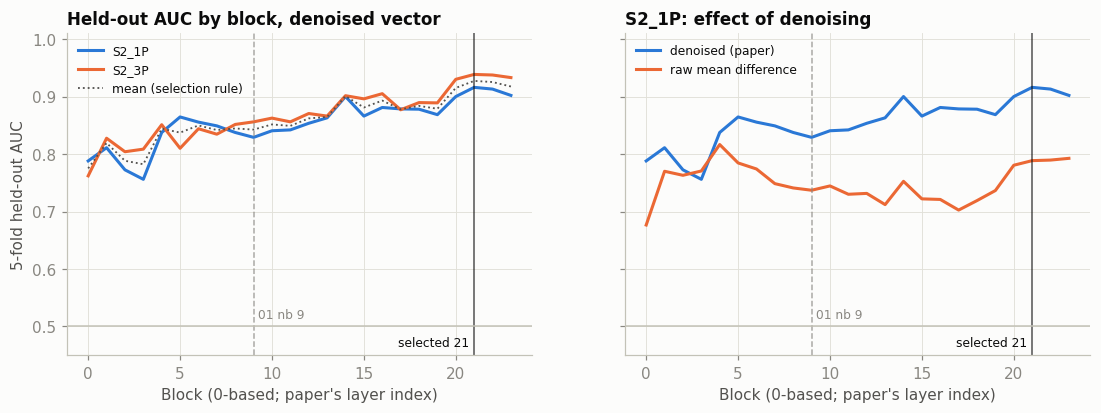

In [12]:
# Plot layer AUC
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
x = np.arange(N_LAYERS)
ax = axes[0]
for ds, col in [("S2_1P", CONTROL_COLOR), ("S2_3P", PAIN_COLOR)]:
    ax.plot(x, curve(ds).values, color=col, label=ds)
ax.plot(x, selection.values, color=INK2, linewidth=1.2, linestyle=":", label="mean (selection rule)")
ax.set_title("Held-out AUC by block, denoised vector")
ax = axes[1]
for (vname, col) in [("denoised (paper)", CONTROL_COLOR), ("raw mean difference", PAIN_COLOR)]:
    ax.plot(x, curve("S2_1P", vname).values, color=col, label=vname)
ax.set_title("S2_1P: effect of denoising")
y_lo = min(0.45, curves["auc"].min() - 0.03)
for ax in axes:
    for b, lab, col, ls, dy in [(BEST_LAYER, f"selected {BEST_LAYER}", INK, "-", 0.01), (PILOT_BLOCK, f"01 nb {PILOT_BLOCK}", MUTED, "--", 0.06)]:
        ax.axvline(b, color=col, linewidth=1, linestyle=ls, alpha=0.7)
        right = b > 0.75 * (N_LAYERS - 1)
        ax.text(b + (-0.25 if right else 0.25), y_lo + dy, lab, color=col, fontsize=8, ha="right" if right else "left", va="bottom")
    ax.axhline(0.5, color=AXIS, linewidth=1)
    ax.set(xlabel="Block (0-based; paper's layer index)", ylim=(y_lo, 1.01))
    ax.legend(loc="upper left", fontsize=8, ncol=1)
axes[0].set_ylabel("5-fold held-out AUC")
show_plot(fig)


## C. Random-direction baseline

,null,median,95th pct,99th pct,max,observed,p-value
0,random unit direction (n=1000),0.487,0.6604,0.7364,0.8027,0.916,0.001


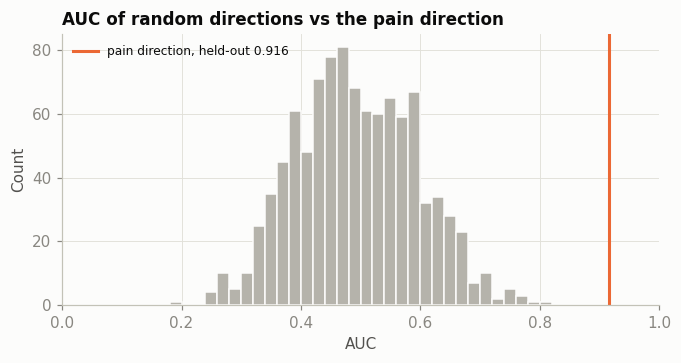

In [13]:
# Test random directions
X_best = FT["S2_1P"][:, BEST_LAYER]
observed = cross_validate(X_best, cats2, sets2)
rng = np.random.default_rng(SEED)

R = rng.standard_normal((N_RANDOM_DIRECTIONS, D_MODEL))
R /= np.linalg.norm(R, axis=1, keepdims=True)
rand_scores = X_best @ R.T
rand_aucs = np.array([pain_auc(rand_scores[:, i], cats2) for i in range(N_RANDOM_DIRECTIONS)])
rand_p = (1 + np.sum(rand_aucs >= observed["auc"])) / (1 + N_RANDOM_DIRECTIONS)

display(pd.DataFrame([{"null": f"random unit direction (n={N_RANDOM_DIRECTIONS})", "median": np.median(rand_aucs),
                       "95th pct": np.percentile(rand_aucs, 95), "99th pct": np.percentile(rand_aucs, 99),
                       "max": rand_aucs.max(), "observed": observed["auc"], "p-value": rand_p}]).round(4))

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(rand_aucs, bins=np.linspace(0, 1, 51), color=NULL_COLOR, edgecolor="#fcfcfb", linewidth=1)
ax.axvline(observed["auc"], color=PAIN_COLOR, label=f"pain direction, held-out {observed['auc']:.3f}")
ax.set(title="AUC of random directions vs the pain direction", xlabel="AUC", ylabel="Count", xlim=(0, 1.0))
ax.legend(loc="upper left", fontsize=8)
show_plot(fig)

## D. Pain vs individual controls


,control,held-out AUC (OOF),95% CI,in-sample AUC,Qwen2.5-7B in-sample
0,B Fear,0.924,"[0.852, 0.979]",0.954,0.977
1,C1 Negative Emotion,0.886,"[0.819, 0.946]",0.923,0.982
2,C2 Negative World State,0.902,"[0.848, 0.952]",0.941,0.984
3,D Neutral,0.986,"[0.964, 1.000]",0.996,1.000
4,E Non-painful Body Sensation,0.919,"[0.876, 0.957]",0.952,0.983


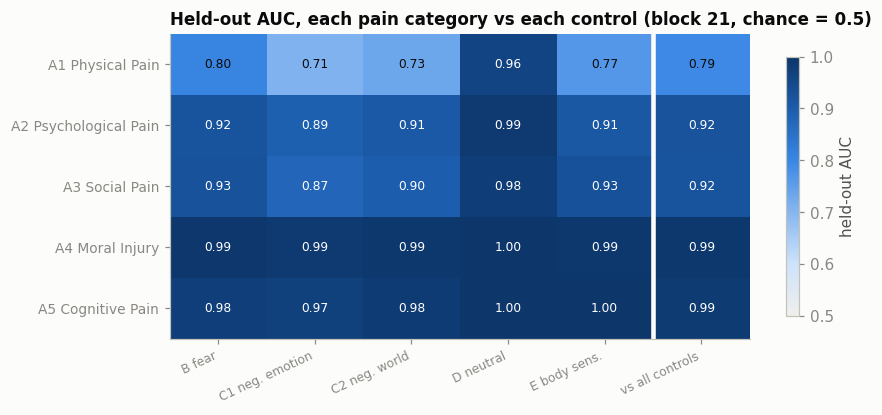

In [14]:
# Compare pain and controls
oof = observed["oof"]
FINAL_VEC, FINAL_K = pain_vector(X_best, cats2)
in_scores = X_best @ unit(FINAL_VEC)

spec = pd.DataFrame([{"control": f"{c} {LABELS[c]}",
                      "held-out AUC (OOF)": pain_auc(oof, cats2, neg=[c]),
                      "95% CI": fmt_ci(bootstrap_auc_ci(oof, cats2, sets2, neg=[c])),
                      "in-sample AUC": pain_auc(in_scores, cats2, neg=[c]),
                      "Qwen2.5-7B in-sample": QWEN7B["per_control_in"][c]} for c in CONTROL])
display(spec.round(3))

SHORT = {"B": "fear", "C1": "neg. emotion", "C2": "neg. world", "D": "neutral", "E": "body sens."}
heat = pd.DataFrame([[pain_auc(oof, cats2, pos=[a], neg=[c]) for c in CONTROL] for a in PAIN],
                    index=[f"{a} {LABELS[a]}" for a in PAIN], columns=[f"{c} {SHORT[c]}" for c in CONTROL])
heat["vs all controls"] = [pain_auc(oof, cats2, pos=[a]) for a in PAIN]

from matplotlib.colors import LinearSegmentedColormap
blues = LinearSegmentedColormap.from_list("seq_blue", ["#f0efec", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
fig, ax = plt.subplots(figsize=(8.5, 3.6))
im = ax.imshow(heat.values, cmap=blues, vmin=0.5, vmax=1.0, aspect="auto")
ax.set_xticks(range(heat.shape[1]), heat.columns, fontsize=8, rotation=25, ha="right")
ax.set_yticks(range(heat.shape[0]), heat.index, fontsize=9)
ax.grid(False)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="#ffffff" if v > 0.85 else INK)
ax.axvline(len(CONTROL) - 0.5, color="#fcfcfb", linewidth=3)
fig.colorbar(im, ax=ax, label="held-out AUC", shrink=0.85)
ax.set_title(f"Held-out AUC, each pain category vs each control (block {BEST_LAYER}, chance = 0.5)")
show_plot(fig)


## E. Transfer to other sentence sets


,metric,ours,95% CI,Qwen2.5-7B,paper range
0,S2_1P 5-fold held-out,0.916,,0.968,0.91-1.00
1,S2_1P in-sample,0.953,,0.985,0.93-1.00
2,S2 vector -> S2_3P (transfer),0.940,"[0.914, 0.962]",0.932,0.91-0.98
3,S2 vector -> S1_1P (transfer),0.844,"[0.787, 0.902]",NaN,
4,S2 vector -> S1_3P (transfer),0.873,"[0.825, 0.922]",NaN,
5,"S1 own vector, 5-fold held-out (mean 1P/3P)",0.864,,0.905,0.85-0.94
6,S1 vector on S1_1P (paper's S1 in-sample),0.892,,0.947,0.87-0.98
7,S1 vector on S1_3P (paper's S1 in-sample),0.873,,0.849,


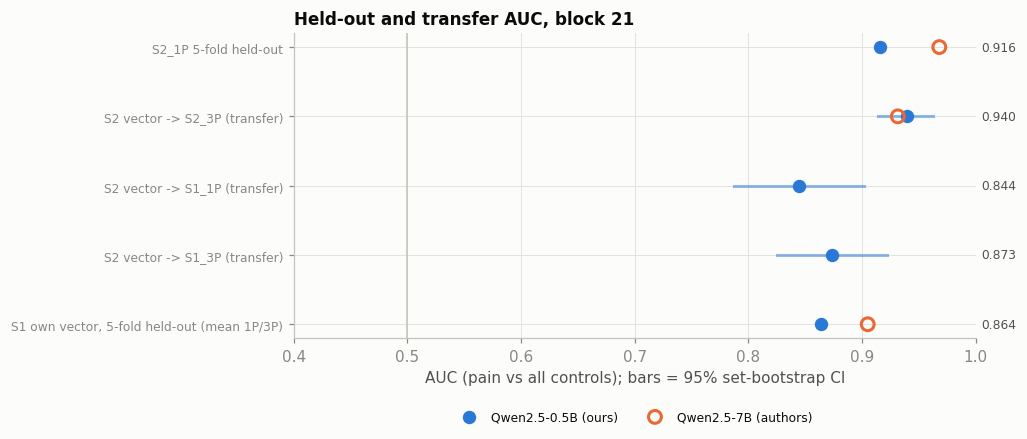

In [15]:
# Test other sentence sets
transfer = []
def add(metric, value, ci=None, ref=None, paper=None):
    transfer.append({"metric": metric, "ours": value, "95% CI": fmt_ci(ci) if ci is not None else "",
                     "Qwen2.5-7B": ref, "paper range": f"{paper[0]:.2f}-{paper[1]:.2f}" if paper else ""})

cv1p = observed
add("S2_1P 5-fold held-out", cv1p["auc"], None, QWEN7B["S2_1P cv"], PAPER_RANGE["S2 held-out AUC (5-fold)"])
add("S2_1P in-sample", pain_auc(in_scores, cats2), None, QWEN7B["S2_1P in"], PAPER_RANGE["S2 in-sample AUC"])
for ds, ref, paper in [("S2_3P", QWEN7B["S2_3P transfer"], PAPER_RANGE["S2 vector -> S2 third person"]),
                       ("S1_1P", None, None), ("S1_3P", None, None)]:
    sc = FT[ds][:, BEST_LAYER] @ unit(FINAL_VEC)
    add(f"S2 vector -> {ds} (transfer)", pain_auc(sc, CATS[ds]), bootstrap_auc_ci(sc, CATS[ds], SETS[ds]), ref, paper)
s1cv = [cross_validate(FT[ds][:, BEST_LAYER], CATS[ds], SETS[ds])["auc"] for ds in ["S1_1P", "S1_3P"]]
add("S1 own vector, 5-fold held-out (mean 1P/3P)", float(np.mean(s1cv)), None, QWEN7B["S1 cv"], PAPER_RANGE["S1 held-out AUC (5-fold)"])
S1_VEC, _ = pain_vector(FT["S1_1P"][:, BEST_LAYER], CATS["S1_1P"])
for ds, ref in [("S1_1P", QWEN7B["S1_1P in"]), ("S1_3P", QWEN7B["S1_3P in"])]:
    add(f"S1 vector on {ds} (paper's S1 in-sample)", pain_auc(FT[ds][:, BEST_LAYER] @ unit(S1_VEC), CATS[ds]), None, ref,
        PAPER_RANGE["S1 in-sample AUC"] if ds == "S1_1P" else None)
transfer = pd.DataFrame(transfer)
display(transfer.round(3))

fig, ax = plt.subplots(figsize=(8, 3.6))
plot_rows = transfer[transfer["metric"].str.contains("held-out|transfer")].reset_index(drop=True)
for i, r in plot_rows.iterrows():
    if r["95% CI"]:
        lo, hi = [float(v) for v in r["95% CI"].strip("[]").split(",")]
        ax.plot([lo, hi], [i, i], color=CONTROL_COLOR, linewidth=2, alpha=0.5)
    ax.scatter(r["ours"], i, color=CONTROL_COLOR, s=60, zorder=3, label="Qwen2.5-0.5B (ours)" if i == 0 else None)
    if pd.notna(r["Qwen2.5-7B"]):
        ax.scatter(r["Qwen2.5-7B"], i, facecolors="none", edgecolors=PAIN_COLOR, s=70, linewidths=2, zorder=3,
                   label="Qwen2.5-7B (authors)" if i == 0 else None)
    ax.text(1.005, i, f"{r['ours']:.3f}", va="center", fontsize=8, color=INK2)
ax.axvline(0.5, color=AXIS, linewidth=1)
ax.set_yticks(range(len(plot_rows)), plot_rows["metric"], fontsize=8)
ax.invert_yaxis()
ax.set(xlim=(0.4, 1.0), xlabel="AUC (pain vs all controls); bars = 95% set-bootstrap CI",
       title=f"Held-out and transfer AUC, block {BEST_LAYER}")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=8)
show_plot(fig)


## F. Z-scores


,z,Qwen2.5-7B
S2_1P pain,0.761,0.827
S2_1P control,-0.761,-0.827
S2_3P pain,0.424,NaN
S2_3P control,-0.747,NaN
S1_1P pain,0.365,NaN
S1_1P control,-0.567,NaN
S1_3P pain,0.093,NaN
S1_3P control,-0.839,NaN
Numb_1P,-0.126,0.124
Numb_3P,-0.315,-0.126


S2_1P mean z per category: {'A1': -0.08, 'A2': 0.7, 'A3': 0.76, 'A4': 1.36, 'A5': 1.07, 'B': -0.87, 'C1': -0.6, 'C2': -0.55, 'D': -1.21, 'E': -0.58}
Numb_1P z = -0.13:  below S2 pain (+0.76)? True | above S2 controls (-0.76)? True | above random/arousal? True | vs A1 physical pain (matched events) -0.08


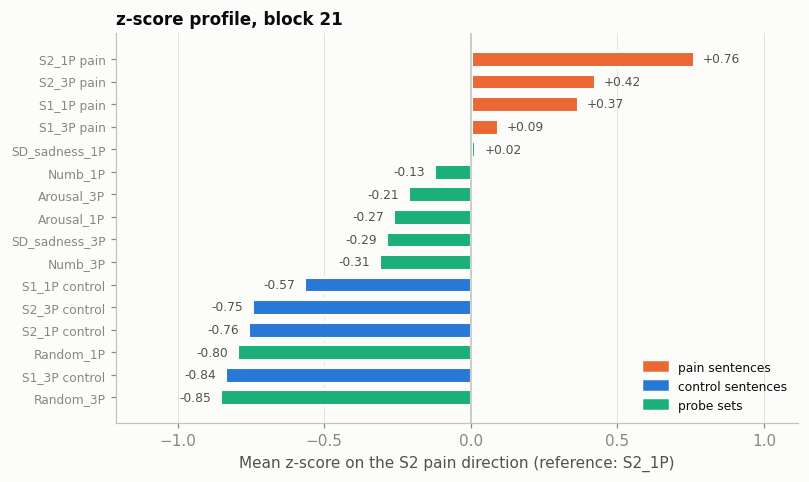

In [16]:
# Compare projection z-scores
u_final = unit(FINAL_VEC)
ref = FT["S2_1P"][:, BEST_LAYER] @ u_final
z = lambda ds: (FT[ds][:, BEST_LAYER] @ u_final - ref.mean()) / ref.std()
Z = {}
for ds in ["S2_1P", "S2_3P", "S1_1P", "S1_3P"]:
    zz = z(ds)
    Z[f"{ds} pain"] = zz[np.isin(CATS[ds], PAIN)].mean()
    Z[f"{ds} control"] = zz[np.isin(CATS[ds], CONTROL)].mean()
for ds in ["Numb_1P", "Numb_3P", "SD_sadness_1P", "SD_sadness_3P", "Arousal_1P", "Arousal_3P", "Random_1P", "Random_3P"]:
    Z[ds] = z(ds).mean()
z_s2 = z("S2_1P")
Z_CAT = {c: z_s2[cats2 == c].mean() for c in PAIN + CONTROL}
zdf = pd.DataFrame({"z": Z}).assign(**{"Qwen2.5-7B": pd.Series({"S2_1P pain": QWEN7B["z"]["S2 pain"], "S2_1P control": QWEN7B["z"]["S2 control"],
                                                               **{k: v for k, v in QWEN7B["z"].items() if "_" in k}})})
display(zdf.round(3))
print("S2_1P mean z per category:", {c: round(float(v), 2) for c, v in Z_CAT.items()})
numb = Z["Numb_1P"]
print(f"Numb_1P z = {numb:+.2f}:  below S2 pain ({Z['S2_1P pain']:+.2f})? {numb < Z['S2_1P pain']} | "
      f"above S2 controls ({Z['S2_1P control']:+.2f})? {numb > Z['S2_1P control']} | "
      f"above random/arousal? {numb > max(Z['Random_1P'], Z['Arousal_1P'])} | "
      f"vs A1 physical pain (matched events) {Z_CAT['A1']:+.2f}")

group_color = lambda k: PAIN_COLOR if "pain" in k else (CONTROL_COLOR if "control" in k else THIRD_COLOR)
items = sorted(Z.items(), key=lambda kv: kv[1])
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(range(len(items)), [v for _, v in items], color=[group_color(k) for k, _ in items], height=0.7, edgecolor="#fcfcfb", linewidth=2)
ax.set_yticks(range(len(items)), [k for k, _ in items], fontsize=8)
ax.axvline(0, color=AXIS, linewidth=1)
for i, (k, v) in enumerate(items):
    ax.text(v + (0.03 if v >= 0 else -0.03), i, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=8, color=INK2)
vals = [v for _, v in items]
pad = 0.22 * (max(vals) - min(vals))
ax.set_xlim(min(min(vals), 0) - pad, max(max(vals), 0) + pad)
ax.set(xlabel="Mean z-score on the S2 pain direction (reference: S2_1P)", title=f"z-score profile, block {BEST_LAYER}")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=PAIN_COLOR, label="pain sentences"), Patch(color=CONTROL_COLOR, label="control sentences"),
                   Patch(color=THIRD_COLOR, label="probe sets")], loc="lower right", fontsize=8)
ax.grid(axis="y", visible=False)
show_plot(fig)


## G. Similarity to other directions


In [17]:
# Compare related directions
POOL = ["S1_1P", "S2_1P", "ControlSupplement_1P"]
rows_at = lambda ds, keep=None: FT[ds][:, BEST_LAYER] if keep is None else FT[ds][:, BEST_LAYER][np.isin(CATS[ds], keep)]
neutral = np.concatenate([rows_at(ds, [NEUTRAL]) for ds in POOL])
n_mean, n_basis = neutral.mean(0), denoise_basis(neutral)
control_vec = lambda a: (lambda v: v - n_basis.T @ (n_basis @ v))(a.mean(0) - n_mean)
pooled = lambda cat: np.concatenate([rows_at(ds, [cat]) for ds in POOL])
DIRS = {"S1_pain": S1_VEC, "S2_pain": FINAL_VEC,
        "Fear": control_vec(pooled("B")), "NegEmotion": control_vec(pooled("C1")),
        "NegWorld": control_vec(pooled("C2")), "BodySens": control_vec(pooled("E")),
        "Arousal": control_vec(rows_at("Arousal_1P")), "Random": control_vec(rows_at("Random_1P")),
        "Numb": control_vec(rows_at("Numb_1P")), "Sadness": control_vec(rows_at("SD_sadness_1P"))}
names = list(DIRS)
COS = pd.DataFrame([[float(unit(DIRS[a]) @ unit(DIRS[b])) for b in names] for a in names], index=names, columns=names)
display(pd.DataFrame([{"pair": f"{a} x {b}", "ours": COS.loc[a, b], "paper mean (25 models)": p, "Qwen2.5-7B": q}
                      for (a, b), (p, q) in PAPER_COSINE.items()]).round(3))

,pair,ours,paper mean (25 models),Qwen2.5-7B
0,S1_pain x S2_pain,0.608,0.61,0.707
1,S2_pain x Fear,0.285,0.12,0.129
2,S2_pain x NegEmotion,0.303,0.21,0.238
3,S1_pain x Fear,0.377,0.09,0.223
4,S1_pain x NegEmotion,0.182,0.06,0.121
5,S2_pain x Sadness,0.315,0.38,0.373
6,Fear x NegEmotion,0.718,0.68,0.668
7,NegEmotion x NegWorld,0.652,0.73,0.747
8,Sadness x NegEmotion,0.675,0.50,0.414


## H. Unembedding

In [18]:
# Inspect top tokens
W_U = model.get_output_embeddings().weight.detach().float().cpu()
logit_scores = W_U @ torch.tensor(u_final, dtype=torch.float32)
top_n = min(30, len(logit_scores) // 2)
top, bot = torch.topk(logit_scores, top_n), torch.topk(-logit_scores, top_n)
unemb = pd.DataFrame({"promoted": [repr(tokenizer.decode([i])) for i in top.indices.tolist()],
                      "score": top.values.numpy().round(3),
                      "demoted": [repr(tokenizer.decode([i])) for i in bot.indices.tolist()],
                      "score ": (-bot.values).numpy().round(3)})
display(unemb.head(20))
PAPER_WORDS = ["hurt", "shame", "guilt", "worthless", "rejected", "hollow", "pain", "ashamed", "lonely", "betray"]
top200 = [tokenizer.decode([i]).strip().lower() for i in torch.topk(logit_scores, min(200, len(logit_scores))).indices.tolist()]
print("paper keywords found in our top-200 promoted tokens:", sorted({w for w in PAPER_WORDS for t in top200 if t.startswith(w)}))


,promoted,score,demoted,score
0,'否认',0.058,' Alert',-0.068
1,'扭曲',0.055,'ynchronize',-0.066
2,' Achilles',0.055,'ibrate',-0.063
3,' flawed',0.055,'平安',-0.062
4,'egot',0.055,'/alert',-0.062
5,'背叛',0.054,' indoors',-0.062
6,'igli',0.053,' alert',-0.061
7,' flaws',0.053,'_increase',-0.061
8,' denying',0.052,'oor',-0.061
9,'抄袭',0.052,'注意',-0.061


paper keywords found in our top-200 promoted tokens: ['betray', 'hurt', 'rejected']
